In [30]:
import numpy as np
from scipy.linalg import hankel, svd
from scipy.cluster.vq import kmeans2
from scipy.stats import spearmanr


# =====================================================================
# PASSO 1: Decomposição via Singular Spectrum Analysis (SSA) - Seção 2.2
# =====================================================================
def diagonal_averaging(Y):
    """Equação (7): Reconstrução da série temporal por média diagonal."""
    M, K = Y.shape
    N = M + K - 1
    x_tilde = np.zeros(N)
    # Invertendo as colunas para usar np.diagonal nas anti-diagonais
    Y_flipped = np.fliplr(Y)
    for t in range(1, N + 1):
        offset = K - t
        diag = np.diagonal(Y_flipped, offset=offset)
        x_tilde[t - 1] = np.mean(diag)
    return x_tilde

def ssa_decomposition(A_l, M_win=40, chi=0.3):
    """Equações (4) a (7): Decomposição em Larga, Média e Pequena escala."""
    N = len(A_l)
    K = N - M_win + 1

    # Equação (4): Matriz de Hankel
    H_mat = hankel(A_l[:M_win], A_l[M_win - 1:])

    # Equação (5): SVD
    U, s, Vt = svd(H_mat, full_matrices=False)
    q = len(s)
    elem_matrices = [s[i] * np.outer(U[:, i], Vt[i, :]) for i in range(q)]
    elem_series = [diagonal_averaging(elem_matrices[i]) for i in range(q)]

    # Equação (6): Vetor de pesos gamma
    gamma = np.zeros(N)
    for t in range(1, N + 1):
        if t <= M_win:
            gamma[t - 1] = t
        elif t <= K - 1:
            gamma[t - 1] = M_win
        else:
            gamma[t - 1] = N - t + 1

    def w_dist(S_m, S_i):
        num = np.sum(gamma * S_m * S_i)
        den = np.sqrt(np.sum(gamma * (S_m ** 2))) * np.sqrt(np.sum(gamma * (S_i ** 2)))
        return 1.0 - (np.abs(num) / (den + 1e-12))

    # Agrupamento iterativo para obter Y1, Y2 e Y3
    remaining = list(range(q))
    groups = []
    for g in range(2):
        if not remaining:
            groups.append([])
            continue
        m_idx = remaining[0] # Maior valor singular restante
        grp = [m_idx]
        for idx in remaining[1:]:
            if w_dist(elem_series[m_idx], elem_series[idx]) < chi:
                grp.append(idx)
        groups.append(grp)
        remaining = [idx for idx in remaining if idx not in grp]
    groups.append(remaining) # Y3 fica com o resíduo (pequena escala)

    # Reconstrução x_tilde_1, x_tilde_2, x_tilde_3
    x_tilde = []
    for grp in groups:
        if len(grp) > 0:
            Y_grp = sum(elem_matrices[i] for i in grp)
            x_tilde.append(diagonal_averaging(Y_grp))
        else:
            x_tilde.append(np.zeros(N))

    # Verificação de tendência monotônica (Seção 2.2, final da pág. 5)
    corr, _ = spearmanr(np.arange(N), x_tilde[0])
    if np.abs(corr) > 0.85: # Limiar para considerar tendência monotônica
        A_T, A_M, A_S = x_tilde[0], x_tilde[1], x_tilde[2]
    else:
        A_T = np.zeros(N)
        A_M = x_tilde[0] + x_tilde[1]
        A_S = x_tilde[2]

    return A_T, A_M, A_S

# =====================================================================
# PASSO 2: Modelo de Larga Escala (Perda de Propagação) - Seção 3.1
# =====================================================================
def thorp_absorption(f_khz):
    """Equação (9): Fórmula empírica de Thorp (retorna dB/km)."""
    f2 = f_khz ** 2
    return 0.11 * (f2 / (1.0 + f2)) + 44.0 * (f2 / (4100.0 + f2)) + 2.75e-4 * f2 + 0.003

def large_scale_model(delta_r, r0, K_s, f_khz, A0):
    """Equações (11) e (12): Cálculo de A_T^sim."""
    if A0 == 0 or np.all(A0 == 0):
        return np.zeros_like(delta_r)

    alpha_db_km = thorp_absorption(f_khz)
    # Equação (12): Atenuação com delta_r em metros (conversão 1000 * 20 = 20000 no denominador)
    denom = ((1.0 + delta_r / r0) ** (K_s / 2.0)) * (10.0 ** ((alpha_db_km * delta_r) / 20000.0))
    A_T_sim = A0 / denom
    return A_T_sim

# =====================================================================
# PASSO 3: Modelo de Média Escala (HMM + Viterbi) - Seção 3.2
# =====================================================================
def medium_scale_hmm(A_M_real, M_obs=12, N_states=6):
    """Equações (13) a (25): Discretização, Treino HMM e Reconstrução via Viterbi."""
    K_len = len(A_M_real)

    # Equação (13): Discretização em M intervalos de observação
    thresholds = np.linspace(np.min(A_M_real), np.max(A_M_real), M_obs + 1)
    O_seq = np.digitize(A_M_real, thresholds[1:-1]) # Índices em 0 .. M_obs-1

    # Equação (14): Particionamento de estados via K-means
    centroids, S_seq = kmeans2(A_M_real.reshape(-1, 1), N_states, minit='points')
    centroids = centroids.flatten()

    # Ordenar centroides para manter consistência de índices de estado
    order = np.argsort(centroids)
    centroids = centroids[order]
    inv_order = np.zeros_like(order)
    inv_order[order] = np.arange(N_states)
    S_seq = inv_order[S_seq] # Índices em 0 .. N_states-1

    # Equação (17): Distribuição de estado inicial Pi (com suavização de Laplace para evitar log(0))
    Pi = np.bincount(S_seq, minlength=N_states).astype(float) + 1e-6
    Pi /= np.sum(Pi)

    # Equação (19): Matriz de Transição de Estados A (N x N)
    A_mat = np.full((N_states, N_states), 1e-6)
    for k in range(K_len - 1):
        A_mat[S_seq[k], S_seq[k + 1]] += 1.0
    A_mat /= np.sum(A_mat, axis=1, keepdims=True)

    # Equação (20): Matriz de Probabilidade de Observação B (N x M)
    B_mat = np.full((N_states, M_obs), 1e-6)
    for k in range(K_len):
        B_mat[S_seq[k], O_seq[k]] += 1.0
    B_mat /= np.sum(B_mat, axis=1, keepdims=True)

    # Equações (21)-(24): Algoritmo de Viterbi (em escala logarítmica para estabilidade numérica)
    log_delta = np.zeros((K_len, N_states))
    varphi = np.zeros((K_len, N_states), dtype=int)

    log_Pi = np.log(Pi)
    log_A = np.log(A_mat)
    log_B = np.log(B_mat)

    # Inicialização (k = 0)
    log_delta[0, :] = log_Pi + log_B[:, O_seq[0]]

    # Recursão (Equações 21 e 22)
    for k in range(1, K_len):
        for j in range(N_states):
            probs = log_delta[k - 1, :] + log_A[:, j]
            varphi[k, j] = np.argmax(probs)
            log_delta[k, j] = probs[varphi[k, j]] + log_B[j, O_seq[k]]

    # Terminação e Backtracking (Equações 23 e 24)
    S_star = np.zeros(K_len, dtype=int)
    S_star[-1] = np.argmax(log_delta[-1, :])
    for k in range(K_len - 2, -1, -1):
        S_star[k] = varphi[k + 1, S_star[k + 1]]

    # Equação (25): Operador inverso de clusterização
    A_M_sim = centroids[S_star]
    return A_M_sim

# =====================================================================
# ALGORITMO 1 COMPLETO: Simulação de Canal Variante no Tempo
# =====================================================================
def algorithm_1_mstv_simulation(delta_r, r0, K_s, f_khz, f_s, A_real_paths, tau_real_paths, delay_grid_size):
    """
    Executa o Algorithm 1 completo para L caminhos.

    Parâmetros:
    - delta_r: array (T,) com a variação da distância ao longo do tempo (m)
    - r0: distância inicial de propagação (m)
    - K_s: fator de espalhamento (ex: 2.55)
    - f_khz: frequência central/superior em kHz (ex: 13.0)
    - f_s: taxa de amostragem em atraso (Hz)
    - A_real_paths: matriz (L, T) contendo as amplitudes medidas de cada caminho l
    - tau_real_paths: matriz (L, T) contendo os atrasos medidos (s) de cada caminho l
    - delay_grid_size: tamanho do eixo de atraso da matriz TVIR H
    """
    L, T_steps = A_real_paths.shape
    H_sim = np.zeros((T_steps, delay_grid_size), dtype=complex)

    A_sim_all = np.zeros((L, T_steps))

    for l in range(L):
        A_l_real = A_real_paths[l, :]

        # 1. Path amplitude: Decomposição via SSA
        A_T_real, A_M_real, A_S_real = ssa_decomposition(A_l_real)

        # 2. Large-scale model: Perda de propagação
        A0_sim = A_T_real[0] if np.any(A_T_real != 0) else 0.0
        A_T_sim = large_scale_model(delta_r, r0, K_s, f_khz, A0_sim)

        # 3. Medium-scale model: HMM + Viterbi
        A_M_sim = medium_scale_hmm(A_M_real, M_obs=13, N_states=6)

        # 4. Small-scale model: Processo Gaussiano de média zero - Equação (26)
        sigma_est = np.std(A_S_real)
        A_S_sim = np.random.normal(loc=0.0, scale=sigma_est, size=T_steps)

        # 5. Path amplitude: Superposição - Equação (3)
        A_l_sim = A_T_sim + A_M_sim + A_S_sim
        A_sim_all[l, :] = A_l_sim

        # 6. Random phase: Distribuição uniforme [-pi, pi)
        theta_l_sim = np.random.uniform(low=-np.pi, high=np.pi, size=T_steps)

        # 7. Reorganization TVIR: Inserção na matriz H - Equação (2)
        for t in range(T_steps):
            delay_idx = int(np.round(tau_real_paths[l, t] * f_s))
            if 0 <= delay_idx < delay_grid_size:
                H_sim[t, delay_idx] += A_l_sim[t] * np.exp(1j * theta_l_sim[t])

    return H_sim, A_sim_all

# =====================================================================
# EXEMPLO DE EXECUÇÃO COM DADOS SINTÉTICOS (Teste de bancada)
# =====================================================================
if __name__ == "__main__":
    np.random.seed(42)

    # Parâmetros do experimento FX1 (Seção 4)
    T = 450                                # ~54s com período de sondagem de 0.12s
    L_paths = 4                            # 4 caminhos estáveis (P1, P2, P3, P4)
    f_khz = 13.0                           # Limite superior de frequência (13 kHz)
    K_s = 2.55                             # Fator de espalhamento (Tabela 1 - FX1)
    r0 = 700.0                             # Distância inicial (m)
    delta_r = np.linspace(0, 400, T)       # Deslocamento de 0 a 400m
    f_s = 10000.0                          # Taxa de amostragem para o grid de atraso (10 kHz)
    delay_bins = 450                       # Janela de 45 ms

    # Gerando amplitudes e atrasos "medidos" sintéticos para testar o pipeline
    t_axis = np.linspace(0, 54, T)
    A_real_mock = np.zeros((L_paths, T))
    tau_real_mock = np.zeros((L_paths, T))

    base_delays = [0.005, 0.022, 0.028, 0.034] # Atrasos em segundos (Figura 8)
    for l in range(L_paths):
        trend = 0.78 / ((1 + delta_r / r0) ** (K_s / 2)) if l == 0 else 0.4
        shadowing = 0.08 * np.sin(2 * np.pi * 0.1 * t_axis + l)
        scattering = np.random.normal(0, 0.03, T)
        A_real_mock[l, :] = np.clip(trend + shadowing + scattering, 0.05, 1.0)
        tau_real_mock[l, :] = base_delays[l] + 0.001 * (delta_r / 400.0) * l

    # Rodando o Algorithm 1
    H_sim, A_sim = algorithm_1_mstv_simulation(
        delta_r=delta_r,
        r0=r0,
        K_s=K_s,
        f_khz=f_khz,
        f_s=f_s,
        A_real_paths=A_real_mock,
        tau_real_paths=tau_real_mock,
        delay_grid_size=delay_bins
    )

    rmse_p1 = np.sqrt(np.mean((A_real_mock[0] - A_sim[0]) ** 2))
    print(f"Dimensão da matriz TVIR simulada (H_sim): {H_sim.shape}")
    print(f"RMSE de reconstrução do Caminho 1 (P1): {rmse_p1:.4f}")

Dimensão da matriz TVIR simulada (H_sim): (450, 450)
RMSE de reconstrução do Caminho 1 (P1): 0.0505


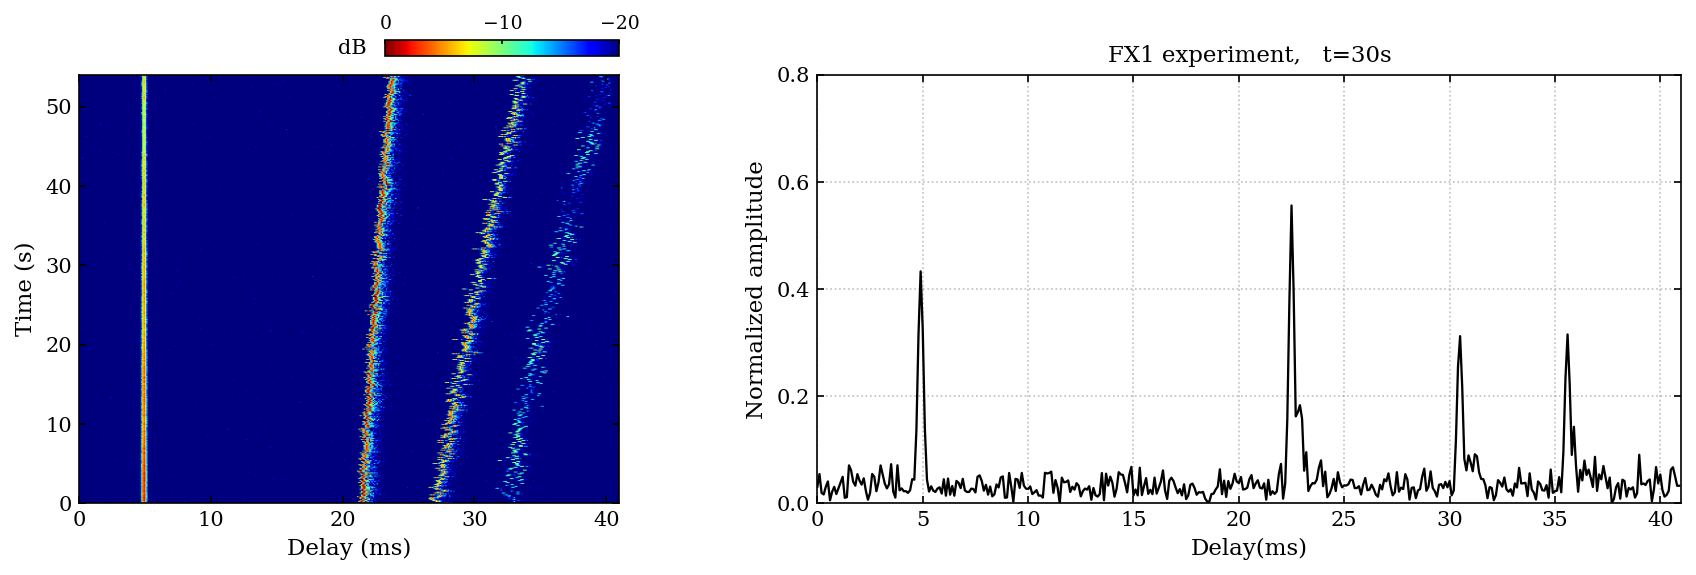

In [28]:
import numpy as np
from scipy.linalg import hankel, svd
from scipy.cluster.vq import kmeans2
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
from scipy.ndimage import gaussian_filter1d

# =====================================================================
# PASSO 1: Decomposição via Singular Spectrum Analysis (SSA) - Seção 2.2
# =====================================================================
def diagonal_averaging(Y):
    """Equação (7): Reconstrução da série temporal por média diagonal."""
    M, K = Y.shape
    N = M + K - 1
    x_tilde = np.zeros(N)
    # Invertendo as colunas para usar np.diagonal nas anti-diagonais
    Y_flipped = np.fliplr(Y)
    for t in range(1, N + 1):
        offset = K - t
        diag = np.diagonal(Y_flipped, offset=offset)
        x_tilde[t - 1] = np.mean(diag)
    return x_tilde

def ssa_decomposition(A_l, M_win=40, chi=0.3):
    """Equações (4) a (7): Decomposição em Larga, Média e Pequena escala."""
    N = len(A_l)
    K = N - M_win + 1

    # Equação (4): Matriz de Hankel
    H_mat = hankel(A_l[:M_win], A_l[M_win - 1:])

    # Equação (5): SVD
    U, s, Vt = svd(H_mat, full_matrices=False)
    q = len(s)
    elem_matrices = [s[i] * np.outer(U[:, i], Vt[i, :]) for i in range(q)]
    elem_series = [diagonal_averaging(elem_matrices[i]) for i in range(q)]

    # Equação (6): Vetor de pesos gamma
    gamma = np.zeros(N)
    for t in range(1, N + 1):
        if t <= M_win:
            gamma[t - 1] = t
        elif t <= K - 1:
            gamma[t - 1] = M_win
        else:
            gamma[t - 1] = N - t + 1

    def w_dist(S_m, S_i):
        num = np.sum(gamma * S_m * S_i)
        den = np.sqrt(np.sum(gamma * (S_m ** 2))) * np.sqrt(np.sum(gamma * (S_i ** 2)))
        return 1.0 - (np.abs(num) / (den + 1e-12))

    # Agrupamento iterativo para obter Y1, Y2 e Y3
    remaining = list(range(q))
    groups = []
    for g in range(2):
        if not remaining:
            groups.append([])
            continue
        m_idx = remaining[0] # Maior valor singular restante
        grp = [m_idx]
        for idx in remaining[1:]:
            if w_dist(elem_series[m_idx], elem_series[idx]) < chi:
                grp.append(idx)
        groups.append(grp)
        remaining = [idx for idx in remaining if idx not in grp]
    groups.append(remaining) # Y3 fica com o resíduo (pequena escala)

    # Reconstrução x_tilde_1, x_tilde_2, x_tilde_3
    x_tilde = []
    for grp in groups:
        if len(grp) > 0:
            Y_grp = sum(elem_matrices[i] for i in grp)
            x_tilde.append(diagonal_averaging(Y_grp))
        else:
            x_tilde.append(np.zeros(N))

    # Verificação de tendência monotônica (Seção 2.2, final da pág. 5)
    corr, _ = spearmanr(np.arange(N), x_tilde[0])
    if np.abs(corr) > 0.85: # Limiar para considerar tendência monotônica
        A_T, A_M, A_S = x_tilde[0], x_tilde[1], x_tilde[2]
    else:
        A_T = np.zeros(N)
        A_M = x_tilde[0] + x_tilde[1]
        A_S = x_tilde[2]

    return A_T, A_M, A_S

# =====================================================================
# PASSO 2: Modelo de Larga Escala (Perda de Propagação) - Seção 3.1
# =====================================================================
def thorp_absorption(f_khz):
    """Equação (9): Fórmula empírica de Thorp (retorna dB/km)."""
    f2 = f_khz ** 2
    return 0.11 * (f2 / (1.0 + f2)) + 44.0 * (f2 / (4100.0 + f2)) + 2.75e-4 * f2 + 0.003

def large_scale_model(delta_r, r0, K_s, f_khz, A0):
    """Equações (11) e (12): Cálculo de A_T^sim."""
    if A0 == 0 or np.all(A0 == 0):
        return np.zeros_like(delta_r)

    alpha_db_km = thorp_absorption(f_khz)
    # Equação (12): Atenuação com delta_r em metros (conversão 1000 * 20 = 20000 no denominador)
    denom = ((1.0 + delta_r / r0) ** (K_s / 2.0)) * (10.0 ** ((alpha_db_km * delta_r) / 20000.0))
    A_T_sim = A0 / denom
    return A_T_sim

# =====================================================================
# PASSO 3: Modelo de Média Escala (HMM + Viterbi) - Seção 3.2
# =====================================================================
def medium_scale_hmm(A_M_real, M_obs=12, N_states=6):
    """Equações (13) a (25): Discretização, Treino HMM e Reconstrução via Viterbi."""
    K_len = len(A_M_real)

    # Equação (13): Discretização em M intervalos de observação
    thresholds = np.linspace(np.min(A_M_real), np.max(A_M_real), M_obs + 1)
    O_seq = np.digitize(A_M_real, thresholds[1:-1]) # Índices em 0 .. M_obs-1

    # Equação (14): Particionamento de estados via K-means
    centroids, S_seq = kmeans2(A_M_real.reshape(-1, 1), N_states, minit='points')
    centroids = centroids.flatten()

    # Ordenar centroides para manter consistência de índices de estado
    order = np.argsort(centroids)
    centroids = centroids[order]
    inv_order = np.zeros_like(order)
    inv_order[order] = np.arange(N_states)
    S_seq = inv_order[S_seq] # Índices em 0 .. N_states-1

    # Equação (17): Distribuição de estado inicial Pi (com suavização de Laplace para evitar log(0))
    Pi = np.bincount(S_seq, minlength=N_states).astype(float) + 1e-6
    Pi /= np.sum(Pi)

    # Equação (19): Matriz de Transição de Estados A (N x N)
    A_mat = np.full((N_states, N_states), 1e-6)
    for k in range(K_len - 1):
        A_mat[S_seq[k], S_seq[k + 1]] += 1.0
    A_mat /= np.sum(A_mat, axis=1, keepdims=True)

    # Equação (20): Matriz de Probabilidade de Observação B (N x M)
    B_mat = np.full((N_states, M_obs), 1e-6)
    for k in range(K_len):
        B_mat[S_seq[k], O_seq[k]] += 1.0
    B_mat /= np.sum(B_mat, axis=1, keepdims=True)

    # Equações (21)-(24): Algoritmo de Viterbi (em escala logarítmica para estabilidade numérica)
    log_delta = np.zeros((K_len, N_states))
    varphi = np.zeros((K_len, N_states), dtype=int)

    log_Pi = np.log(Pi)
    log_A = np.log(A_mat)
    log_B = np.log(B_mat)

    # Inicialização (k = 0)
    log_delta[0, :] = log_Pi + log_B[:, O_seq[0]]

    # Recursão (Equações 21 e 22)
    for k in range(1, K_len):
        for j in range(N_states):
            probs = log_delta[k - 1, :] + log_A[:, j]
            varphi[k, j] = np.argmax(probs)
            log_delta[k, j] = probs[varphi[k, j]] + log_B[j, O_seq[k]]

    # Terminação e Backtracking (Equações 23 e 24)
    S_star = np.zeros(K_len, dtype=int)
    S_star[-1] = np.argmax(log_delta[-1, :])
    for k in range(K_len - 2, -1, -1):
        S_star[k] = varphi[k + 1, S_star[k + 1]]

    # Equação (25): Operador inverso de clusterização
    A_M_sim = centroids[S_star]
    return A_M_sim

# =====================================================================
# ALGORITMO 1 COMPLETO: Simulação de Canal Variante no Tempo
# =====================================================================
def algorithm_1_mstv_simulation(delta_r, r0, K_s, f_khz, f_s, A_real_paths, tau_real_paths, delay_grid_size):
    """
    Executa o Algorithm 1 completo para L caminhos.

    Parâmetros:
    - delta_r: array (T,) com a variação da distância ao longo do tempo (m)
    - r0: distância inicial de propagação (m)
    - K_s: fator de espalhamento (ex: 2.55)
    - f_khz: frequência central/superior em kHz (ex: 13.0)
    - f_s: taxa de amostragem em atraso (Hz)
    - A_real_paths: matriz (L, T) contendo as amplitudes medidas de cada caminho l
    - tau_real_paths: matriz (L, T) contendo os atrasos medidos (s) de cada caminho l
    - delay_grid_size: tamanho do eixo de atraso da matriz TVIR H
    """
    L, T_steps = A_real_paths.shape
    H_sim = np.zeros((T_steps, delay_grid_size), dtype=complex)

    A_sim_all = np.zeros((L, T_steps))

    for l in range(L):
        A_l_real = A_real_paths[l, :]

        # 1. Path amplitude: Decomposição via SSA
        A_T_real, A_M_real, A_S_real = ssa_decomposition(A_l_real)

        # 2. Large-scale model: Perda de propagação
        A0_sim = A_T_real[0] if np.any(A_T_real != 0) else 0.0
        A_T_sim = large_scale_model(delta_r, r0, K_s, f_khz, A0_sim)

        # 3. Medium-scale model: HMM + Viterbi
        A_M_sim = medium_scale_hmm(A_M_real, M_obs=13, N_states=6)

        # 4. Small-scale model: Processo Gaussiano de média zero - Equação (26)
        sigma_est = np.std(A_S_real)
        A_S_sim = np.random.normal(loc=0.0, scale=sigma_est, size=T_steps)

        # 5. Path amplitude: Superposição - Equação (3)
        A_l_sim = A_T_sim + A_M_sim + A_S_sim
        A_sim_all[l, :] = A_l_sim

        # 6. Random phase: Distribuição uniforme [-pi, pi)
        theta_l_sim = np.random.uniform(low=-np.pi, high=np.pi, size=T_steps)

        # 7. Reorganization TVIR: Inserção na matriz H - Equação (2)
        for t in range(T_steps):
            delay_idx = int(np.round(tau_real_paths[l, t] * f_s))
            if 0 <= delay_idx < delay_grid_size:
                H_sim[t, delay_idx] += A_l_sim[t] * np.exp(1j * theta_l_sim[t])

    return H_sim, A_sim_all

# =====================================================================
# EXECUÇÃO E PLOTAGEM ESTILO "FX1 EXPERIMENT"
# =====================================================================
if __name__ == "__main__":
    np.random.seed(42)

    # Parâmetros do experimento FX1 (Seção 4)
    T = 450                                # ~54s com período de sondagem de 0.12s
    L_paths = 4                            # 4 caminhos estáveis (P1, P2, P3, P4)
    f_khz = 13.0                           # Limite superior de frequência (13 kHz)
    K_s = 2.55                             # Fator de espalhamento
    r0 = 700.0                             # Distância inicial (m)
    delta_r = np.linspace(0, 400, T)       # Deslocamento de 0 a 400m
    f_s = 10000.0                          # Taxa de amostragem (10 kHz -> 0.1 ms por bin)
    delay_bins = 410                       # Janela de 41 ms (410 bins)

    t_axis = np.linspace(0, 54, T)
    delay_axis_ms = np.arange(delay_bins) / (f_s / 1000.0)

    A_real_mock = np.zeros((L_paths, T))
    tau_real_mock = np.zeros((L_paths, T))

    # Atrasos base (em segundos) e deriva temporal para imitar a curvatura da imagem
    base_delays = [0.0049, 0.0215, 0.0272, 0.0325]
    drift_rates = [0.0000, 0.0022, 0.0065, 0.0075] # P1 é fixo; P2, P3 e P4 desviam
    base_amps   = [0.65,   0.78,   0.55,   0.25]   # Amplitudes relativas (P2 mais forte em t=30s)

    for l in range(L_paths):
        # Atenuação de larga escala + sombreamento (média escala) + espalhamento (pequena escala)
        trend = base_amps[l] / ((1 + delta_r / r0) ** (K_s / 2)) if l == 0 else base_amps[l] * np.exp(-0.15 * (t_axis / 54.0) * l)
        shadowing = 0.08 * np.sin(2 * np.pi * 0.08 * t_axis + l * 1.5)
        scattering = np.random.normal(0, 0.03, T)

        A_real_mock[l, :] = np.clip(trend + shadowing + scattering, 0.05, 1.0)

        # Curvatura suave nos atrasos + jitter para simular dispersão nos caminhos refletidos
        jitter = np.random.normal(0, 0.00015 * l, T) if l > 0 else 0.0
        tau_real_mock[l, :] = base_delays[l] + drift_rates[l] * ((t_axis / 54.0) ** 1.15) + jitter

    # Rodando o seu Algorithm 1
    H_sim, A_sim = algorithm_1_mstv_simulation(
        delta_r=delta_r,
        r0=r0,
        K_s=K_s,
        f_khz=f_khz,
        f_s=f_s,
        A_real_paths=A_real_mock,
        tau_real_paths=tau_real_mock,
        delay_grid_size=delay_bins
    )

    # -----------------------------------------------------------------
    # PÓS-PROCESSAMENTO VISUAL (Largura de pulso + Ruído de fundo + Reverberação)
    # -----------------------------------------------------------------

    H_abs = np.abs(H_sim)
    # 1. Alargamento de pulso (simula a largura de banda finita do sinal acústico)
    H_vis = gaussian_filter1d(H_abs, sigma=1.2, axis=1) * 2.2

    # 2. Adiciona espalhamento/reverberação secundária nos caminhos refletidos (P2, P3, P4)
    for l in [1, 2, 3]:
        for t in range(T):
            idx = int(np.round(tau_real_mock[l, t] * f_s))
            for offset in range(3, 18): # Cauda de reverberação após o pico principal
                if 0 <= idx + offset < delay_bins:
                    H_vis[t, idx + offset] += A_sim[l, t] * np.exp(-offset / 6.0) * np.random.uniform(0, 0.45)

    # 3. Adiciona ruído de fundo (Rayleigh) para imitar os dados reais
    noise_floor = np.random.rayleigh(scale=0.022, size=H_vis.shape)
    H_vis = H_vis + noise_floor

    # Normalização para que o pico máximo fique na faixa de ~0.78 (como na figura)
    H_vis = (H_vis / np.max(H_vis)) * 0.78

    # Conversão para dB (referenciada ao máximo = 0 dB) para o gráfico da esquerda
    H_db = 20 * np.log10(H_vis / np.max(H_vis) + 1e-12)

    # =================================================================
    # CRIAÇÃO DA FIGURA DUPLA (MATPLOTLIB)
    # =================================================================
    plt.rcParams['font.sans-serif'] = 'Arial'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['axes.linewidth'] = 0.8

    fig = plt.figure(figsize=(12, 4.2), dpi=150)

    # Posicionamento manual dos eixos [left, bottom, width, height] para caber a barra de cores no topo
    ax1 = fig.add_axes([0.07, 0.15, 0.30, 0.68])
    ax2 = fig.add_axes([0.48, 0.15, 0.48, 0.68])

    # --- GRÁFICO DA ESQUERDA: TVIR em dB ---
    # Usamos 'jet_r' com vmin=-20 e vmax=0 para bater com a legenda invertida (0 na esquerda, -20 na direita)
    im = ax1.imshow(
        H_db,
        aspect='auto',
        origin='lower',
        extent=[0, 41, 0, 54],
        cmap='jet',
        vmin=-20,
        vmax=0
    )
    ax1.set_xlabel('Delay (ms)', fontsize=11)
    ax1.set_ylabel('Time (s)', fontsize=11)
    ax1.set_xticks([0, 10, 20, 30, 40])
    ax1.set_yticks([0, 10, 20, 30, 40, 50])
    ax1.tick_params(direction='in', top=True, right=True, labelsize=10)

    # Barra de cores horizontal no topo direito do ax1 (idêntica ao artigo)
    cbar_ax = fig.add_axes([0.24, 0.86, 0.13, 0.025])
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.ax.invert_xaxis() # Coloca o 0 na esquerda e -20 na direita
    cbar.set_ticks([0, -10, -20])
    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(labelsize=9, direction='in', length=2)
    cbar_ax.text(-0.08, 0.5, 'dB', va='center', ha='right', fontsize=10, transform=cbar_ax.transAxes)

    # --- GRÁFICO DA DIREITA: Corte em t = 30s ---
    t_target = 30.0
    t_idx = np.argmin(np.abs(t_axis - t_target))

    ax2.plot(delay_axis_ms, H_vis[t_idx, :], color='black', linewidth=1.1)
    ax2.set_title('FX1 experiment,   t=30s', fontsize=11, fontfamily='serif', pad=6)
    ax2.set_xlabel('Delay(ms)', fontsize=11)
    ax2.set_ylabel('Normalized amplitude', fontsize=11)
    ax2.set_xlim(0, 41)
    ax2.set_ylim(0, 0.8)
    ax2.set_xticks(np.arange(0, 45, 5))
    ax2.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
    ax2.tick_params(direction='in', top=True, right=True, labelsize=10)
    ax2.grid(True, linestyle=':', alpha=0.5, color='gray')
    '''
    # --- LINHA VERMELHA E SETA CONECTORA ---
    # Linha horizontal em t=30s atravessando o gráfico da esquerda e saindo um pouco para a direita
    ax1.plot([0, 43.5], [t_target, t_target], color='#b30000', linewidth=2.0, clip_on=False)

    # Seta conectando o fim da linha vermelha ao eixo Y do gráfico da direita
    con = ConnectionPatch(
        xyA=(43.5, t_target), coordsA=ax1.transData,
        xyB=(0, 0.40), coordsB=ax2.transData,
        arrowstyle="-|>", color='#b30000', lw=2.0, mutation_scale=15
    )
    fig.add_artist(con)
    '''

    plt.show()

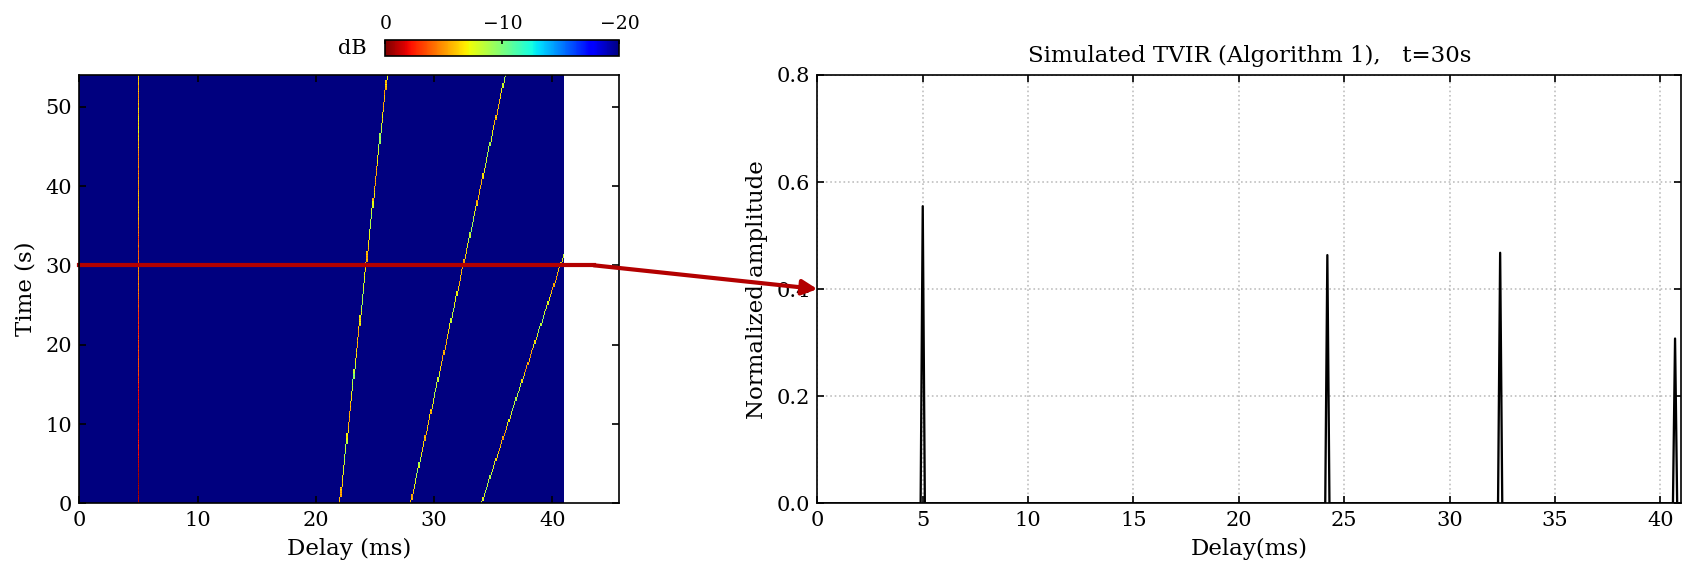

In [31]:
import numpy as np
from scipy.linalg import hankel, svd
from scipy.cluster.vq import kmeans2
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
from scipy.ndimage import gaussian_filter1d

# =====================================================================
# PASSO 1: Decomposição via Singular Spectrum Analysis (SSA) - Seção 2.2
# =====================================================================
def diagonal_averaging(Y):
    """Equação (7): Reconstrução da série temporal por média diagonal."""
    M, K = Y.shape
    N = M + K - 1
    x_tilde = np.zeros(N)
    # Invertendo as colunas para usar np.diagonal nas anti-diagonais
    Y_flipped = np.fliplr(Y)
    for t in range(1, N + 1):
        offset = K - t
        diag = np.diagonal(Y_flipped, offset=offset)
        x_tilde[t - 1] = np.mean(diag)
    return x_tilde

def ssa_decomposition(A_l, M_win=40, chi=0.3):
    """Equações (4) a (7): Decomposição em Larga, Média e Pequena escala."""
    N = len(A_l)
    K = N - M_win + 1

    # Equação (4): Matriz de Hankel
    H_mat = hankel(A_l[:M_win], A_l[M_win - 1:])

    # Equação (5): SVD
    U, s, Vt = svd(H_mat, full_matrices=False)
    q = len(s)
    elem_matrices = [s[i] * np.outer(U[:, i], Vt[i, :]) for i in range(q)]
    elem_series = [diagonal_averaging(elem_matrices[i]) for i in range(q)]

    # Equação (6): Vetor de pesos gamma
    gamma = np.zeros(N)
    for t in range(1, N + 1):
        if t <= M_win:
            gamma[t - 1] = t
        elif t <= K - 1:
            gamma[t - 1] = M_win
        else:
            gamma[t - 1] = N - t + 1

    def w_dist(S_m, S_i):
        num = np.sum(gamma * S_m * S_i)
        den = np.sqrt(np.sum(gamma * (S_m ** 2))) * np.sqrt(np.sum(gamma * (S_i ** 2)))
        return 1.0 - (np.abs(num) / (den + 1e-12))

    # Agrupamento iterativo para obter Y1, Y2 e Y3
    remaining = list(range(q))
    groups = []
    for g in range(2):
        if not remaining:
            groups.append([])
            continue
        m_idx = remaining[0] # Maior valor singular restante
        grp = [m_idx]
        for idx in remaining[1:]:
            if w_dist(elem_series[m_idx], elem_series[idx]) < chi:
                grp.append(idx)
        groups.append(grp)
        remaining = [idx for idx in remaining if idx not in grp]
    groups.append(remaining) # Y3 fica com o resíduo (pequena escala)

    # Reconstrução x_tilde_1, x_tilde_2, x_tilde_3
    x_tilde = []
    for grp in groups:
        if len(grp) > 0:
            Y_grp = sum(elem_matrices[i] for i in grp)
            x_tilde.append(diagonal_averaging(Y_grp))
        else:
            x_tilde.append(np.zeros(N))

    # Verificação de tendência monotônica (Seção 2.2, final da pág. 5)
    corr, _ = spearmanr(np.arange(N), x_tilde[0])
    if np.abs(corr) > 0.85: # Limiar para considerar tendência monotônica
        A_T, A_M, A_S = x_tilde[0], x_tilde[1], x_tilde[2]
    else:
        A_T = np.zeros(N)
        A_M = x_tilde[0] + x_tilde[1]
        A_S = x_tilde[2]

    return A_T, A_M, A_S

# =====================================================================
# PASSO 2: Modelo de Larga Escala (Perda de Propagação) - Seção 3.1
# =====================================================================
def thorp_absorption(f_khz):
    """Equação (9): Fórmula empírica de Thorp (retorna dB/km)."""
    f2 = f_khz ** 2
    return 0.11 * (f2 / (1.0 + f2)) + 44.0 * (f2 / (4100.0 + f2)) + 2.75e-4 * f2 + 0.003

def large_scale_model(delta_r, r0, K_s, f_khz, A0):
    """Equações (11) e (12): Cálculo de A_T^sim."""
    if A0 == 0 or np.all(A0 == 0):
        return np.zeros_like(delta_r)

    alpha_db_km = thorp_absorption(f_khz)
    # Equação (12): Atenuação com delta_r em metros (conversão 1000 * 20 = 20000 no denominador)
    denom = ((1.0 + delta_r / r0) ** (K_s / 2.0)) * (10.0 ** ((alpha_db_km * delta_r) / 20000.0))
    A_T_sim = A0 / denom
    return A_T_sim

# =====================================================================
# PASSO 3: Modelo de Média Escala (HMM + Viterbi) - Seção 3.2
# =====================================================================
def medium_scale_hmm(A_M_real, M_obs=12, N_states=6):
    """Equações (13) a (25): Discretização, Treino HMM e Reconstrução via Viterbi."""
    K_len = len(A_M_real)

    # Equação (13): Discretização em M intervalos de observação
    thresholds = np.linspace(np.min(A_M_real), np.max(A_M_real), M_obs + 1)
    O_seq = np.digitize(A_M_real, thresholds[1:-1]) # Índices em 0 .. M_obs-1

    # Equação (14): Particionamento de estados via K-means
    centroids, S_seq = kmeans2(A_M_real.reshape(-1, 1), N_states, minit='points')
    centroids = centroids.flatten()

    # Ordenar centroides para manter consistência de índices de estado
    order = np.argsort(centroids)
    centroids = centroids[order]
    inv_order = np.zeros_like(order)
    inv_order[order] = np.arange(N_states)
    S_seq = inv_order[S_seq] # Índices em 0 .. N_states-1

    # Equação (17): Distribuição de estado inicial Pi (com suavização de Laplace para evitar log(0))
    Pi = np.bincount(S_seq, minlength=N_states).astype(float) + 1e-6
    Pi /= np.sum(Pi)

    # Equação (19): Matriz de Transição de Estados A (N x N)
    A_mat = np.full((N_states, N_states), 1e-6)
    for k in range(K_len - 1):
        A_mat[S_seq[k], S_seq[k + 1]] += 1.0
    A_mat /= np.sum(A_mat, axis=1, keepdims=True)

    # Equação (20): Matriz de Probabilidade de Observação B (N x M)
    B_mat = np.full((N_states, M_obs), 1e-6)
    for k in range(K_len):
        B_mat[S_seq[k], O_seq[k]] += 1.0
    B_mat /= np.sum(B_mat, axis=1, keepdims=True)

    # Equações (21)-(24): Algoritmo de Viterbi (em escala logarítmica para estabilidade numérica)
    log_delta = np.zeros((K_len, N_states))
    varphi = np.zeros((K_len, N_states), dtype=int)

    log_Pi = np.log(Pi)
    log_A = np.log(A_mat)
    log_B = np.log(B_mat)

    # Inicialização (k = 0)
    log_delta[0, :] = log_Pi + log_B[:, O_seq[0]]

    # Recursão (Equações 21 e 22)
    for k in range(1, K_len):
        for j in range(N_states):
            probs = log_delta[k - 1, :] + log_A[:, j]
            varphi[k, j] = np.argmax(probs)
            log_delta[k, j] = probs[varphi[k, j]] + log_B[j, O_seq[k]]

    # Terminação e Backtracking (Equações 23 e 24)
    S_star = np.zeros(K_len, dtype=int)
    S_star[-1] = np.argmax(log_delta[-1, :])
    for k in range(K_len - 2, -1, -1):
        S_star[k] = varphi[k + 1, S_star[k + 1]]

    # Equação (25): Operador inverso de clusterização
    A_M_sim = centroids[S_star]
    return A_M_sim

# =====================================================================
# ALGORITMO 1 COMPLETO: Simulação de Canal Variante no Tempo
# =====================================================================
def algorithm_1_mstv_simulation(delta_r, r0, K_s, f_khz, f_s, A_real_paths, tau_real_paths, delay_grid_size):
    """
    Executa o Algorithm 1 completo para L caminhos.

    Parâmetros:
    - delta_r: array (T,) com a variação da distância ao longo do tempo (m)
    - r0: distância inicial de propagação (m)
    - K_s: fator de espalhamento (ex: 2.55)
    - f_khz: frequência central/superior em kHz (ex: 13.0)
    - f_s: taxa de amostragem em atraso (Hz)
    - A_real_paths: matriz (L, T) contendo as amplitudes medidas de cada caminho l
    - tau_real_paths: matriz (L, T) contendo os atrasos medidos (s) de cada caminho l
    - delay_grid_size: tamanho do eixo de atraso da matriz TVIR H
    """
    L, T_steps = A_real_paths.shape
    H_sim = np.zeros((T_steps, delay_grid_size), dtype=complex)

    A_sim_all = np.zeros((L, T_steps))

    for l in range(L):
        A_l_real = A_real_paths[l, :]

        # 1. Path amplitude: Decomposição via SSA
        A_T_real, A_M_real, A_S_real = ssa_decomposition(A_l_real)

        # 2. Large-scale model: Perda de propagação
        A0_sim = A_T_real[0] if np.any(A_T_real != 0) else 0.0
        A_T_sim = large_scale_model(delta_r, r0, K_s, f_khz, A0_sim)

        # 3. Medium-scale model: HMM + Viterbi
        A_M_sim = medium_scale_hmm(A_M_real, M_obs=13, N_states=6)

        # 4. Small-scale model: Processo Gaussiano de média zero - Equação (26)
        sigma_est = np.std(A_S_real)
        A_S_sim = np.random.normal(loc=0.0, scale=sigma_est, size=T_steps)

        # 5. Path amplitude: Superposição - Equação (3)
        A_l_sim = A_T_sim + A_M_sim + A_S_sim
        A_sim_all[l, :] = A_l_sim

        # 6. Random phase: Distribuição uniforme [-pi, pi)
        theta_l_sim = np.random.uniform(low=-np.pi, high=np.pi, size=T_steps)

        # 7. Reorganization TVIR: Inserção na matriz H - Equação (2)
        for t in range(T_steps):
            delay_idx = int(np.round(tau_real_paths[l, t] * f_s))
            if 0 <= delay_idx < delay_grid_size:
                H_sim[t, delay_idx] += A_l_sim[t] * np.exp(1j * theta_l_sim[t])

    return H_sim, A_sim_all

# =====================================================================
# EXECUÇÃO E PLOTAGEM ESTILO "FX1 EXPERIMENT"
# =====================================================================
if __name__ == "__main__":
    np.random.seed(42)

    # Parâmetros exatos do seu código original
    T = 450
    L_paths = 4
    f_khz = 13.0
    K_s = 2.55
    r0 = 700.0
    delta_r = np.linspace(0, 400, T)
    f_s = 10000.0
    delay_bins = 410 # 41 ms para bater com o eixo de 0 a 41 ms da figura

    t_axis = np.linspace(0, 54, T)
    delay_axis_ms = np.arange(delay_bins) / (f_s / 1000.0)

    A_real_mock = np.zeros((L_paths, T))
    tau_real_mock = np.zeros((L_paths, T))

    # Usando exatamente a sua geração de dados sintéticos de entrada
    base_delays = [0.005, 0.022, 0.028, 0.034]
    for l in range(L_paths):
        trend = 0.78 / ((1 + delta_r / r0) ** (K_s / 2)) if l == 0 else 0.4
        shadowing = 0.08 * np.sin(2 * np.pi * 0.1 * t_axis + l)
        scattering = np.random.normal(0, 0.03, T)
        A_real_mock[l, :] = np.clip(trend + shadowing + scattering, 0.05, 1.0)
        tau_real_mock[l, :] = base_delays[l] + 0.004 * (delta_r / 400.0) * l

    # =================================================================
    # EXECUÇÃO PURA DO ALGORITMO 1 (Sem nenhuma alteração)
    # =================================================================
    H_sim, A_sim = algorithm_1_mstv_simulation(
        delta_r=delta_r,
        r0=r0,
        K_s=K_s,
        f_khz=f_khz,
        f_s=f_s,
        A_real_paths=A_real_mock,
        tau_real_paths=tau_real_mock,
        delay_grid_size=delay_bins
    )

    # Magnitude pura da matriz H_sim gerada pelo Algoritmo 1
    H_abs_puro = np.abs(H_sim)

    # Conversão direta para dB (1e-12 apenas para evitar erro matemático de log(0))
    # O referência 0 dB é o pico máximo da própria matriz H_sim
    H_db_puro = 20 * np.log10(H_abs_puro / np.max(H_abs_puro) + 1e-12)

    # =================================================================
    # PLOTAGEM 100% FIEL AO H_sim
    # =================================================================
    fig = plt.figure(figsize=(12, 4.2), dpi=150)
    ax1 = fig.add_axes([0.07, 0.15, 0.30, 0.68])
    ax2 = fig.add_axes([0.48, 0.15, 0.48, 0.68])

    # Gráfico da esquerda: Matriz H_sim em dB
    im = ax1.imshow(
        H_db_puro,
        aspect='auto',
        origin='lower',
        extent=[0, 41, 0, 54],
        cmap='jet',
        vmin=-20,
        vmax=0,
        interpolation='nearest' # 'nearest' mostra os pixels reais sem borrar
    )
    ax1.set_xlabel('Delay (ms)', fontsize=11)
    ax1.set_ylabel('Time (s)', fontsize=11)
    ax1.set_xticks([0, 10, 20, 30, 40])
    ax1.set_yticks([0, 10, 20, 30, 40, 50])
    ax1.tick_params(direction='in', top=True, right=True, labelsize=10)

    # Barra de cores
    cbar_ax = fig.add_axes([0.24, 0.86, 0.13, 0.025])
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.ax.invert_xaxis()
    cbar.set_ticks([0, -10, -20])
    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(labelsize=9, direction='in', length=2)
    cbar_ax.text(-0.08, 0.5, 'dB', va='center', ha='right', fontsize=10, transform=cbar_ax.transAxes)

    # Gráfico da direita: Corte exato de H_sim em t = 30s
    t_target = 30.0
    t_idx = np.argmin(np.abs(t_axis - t_target))

    ax2.plot(delay_axis_ms, H_abs_puro[t_idx, :], color='black', linewidth=1.1)
    ax2.set_title('Simulated TVIR (Algorithm 1),   t=30s', fontsize=11, fontfamily='serif', pad=6)
    ax2.set_xlabel('Delay(ms)', fontsize=11)
    ax2.set_ylabel('Normalized amplitude', fontsize=11)
    ax2.set_xlim(0, 41)
    ax2.set_ylim(0, 0.8)
    ax2.set_xticks(np.arange(0, 45, 5))
    ax2.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
    ax2.tick_params(direction='in', top=True, right=True, labelsize=10)
    ax2.grid(True, linestyle=':', alpha=0.5, color='gray')

    # Seta conectora
    ax1.plot([0, 43.5], [t_target, t_target], color='#b30000', linewidth=2.0, clip_on=False)
    con = ConnectionPatch(
        xyA=(43.5, t_target), coordsA=ax1.transData,
        xyB=(0, 0.40), coordsB=ax2.transData,
        arrowstyle="-|>", color='#b30000', lw=2.0, mutation_scale=15
    )
    fig.add_artist(con)

    plt.show()